# 현실의 데이터 06: 자금세탁 거래 탐지

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/06_aml_transactions.ipynb)

**분야**: 금융 · 핀테크 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 자금세탁방지 (AML) · 거래 모니터링 · 계좌 단위 조사

> 은행 거래 508만 건 중 세탁은 0.1%. 거래를 볼까, 계좌를 볼까?

**데이터**: IBM Transactions for Anti Money Laundering (HI-Small) (약 90MB (압축)). IBM (Altman et al., NeurIPS 2023). 사람 · 회사 · 은행이 있는 가상 세계를 시뮬레이션한 합성 거래 5,078,345건, 세탁 표시 포함 (Kaggle 원본, 여기서는 Hugging Face 사본으로 로그인 없이 받는다).

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 거래 한 건 (또는 계좌 하나) |
| ② 입력 X | 시각 · 보낸/받는 은행 · 계좌 · 금액 · 통화 · 결제 형식 |
| ③ 출력 y | 세탁인가 (Is Laundering) |
| ④ 평가지표 | 정밀도 · 재현율 |
| ⑤ 기준선 | 전부 '정상' |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Altman et al. (2023) Realistic Synthetic Financial Transactions for Anti-Money Laundering Models, NeurIPS Datasets and Benchmarks](https://arxiv.org/abs/2306.16424)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

압축 파일 약 90MB, 풀면 약 480MB. 처음엔 몇 분 걸린다 (Colab 메모리로 충분하다).

In [2]:
URL = "https://huggingface.co/datasets/eexzzm/IBM-Transactions-for-Anti-Money-Laundering-HI-Small-Trans/resolve/main/HI-Small_Trans.csv.zip"
with zipfile.ZipFile(download(URL, "data/HI-Small_Trans.csv.zip")) as z:
    df = pd.read_csv(z.open("HI-Small_Trans.csv"))
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
print(df.shape, df["Timestamp"].min(), "~", df["Timestamp"].max())
df.sample(5, random_state=0)

(5078345, 11) 2022-09-01 00:00:00 ~ 2022-09-18 16:18:00


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
3012533,2022-09-06 11:30:00,18196,803625250,19723,80397E700,17221.08,Yuan,17221.08,Yuan,Cheque,0
2148015,2022-09-04 06:47:00,211,80A722860,28416,80A6BA170,0.01,Australian Dollar,0.01,Australian Dollar,Wire,0
4044898,2022-09-08 15:22:00,24144,80258F390,1655,80DE48C90,1446.94,Euro,1446.94,Euro,Credit Card,0
3838179,2022-09-08 04:37:00,1,80D4327D0,146265,81322BCE0,33.29,US Dollar,33.29,US Dollar,ACH,0
3573743,2022-09-07 15:55:00,29467,8039B33D0,210261,80457A8D0,37731.56,Yen,37731.56,Yen,Cheque,0


## 열어 보기

세탁 비율, 결제 형식 · 통화별 세탁 비율. 날짜마다 거래 수는?

transactions 5,078,345, laundering 5,177 (0.102%)
                    mean   sum     size
Payment Format                         
ACH             0.007462  4483   600797
Bitcoin         0.000383    56   146091
Cash            0.000220   108   490891
Cheque          0.000174   324  1864331
Credit Card     0.000156   206  1323324
Reinvestment    0.000000     0   481056
Wire            0.000000     0   171855


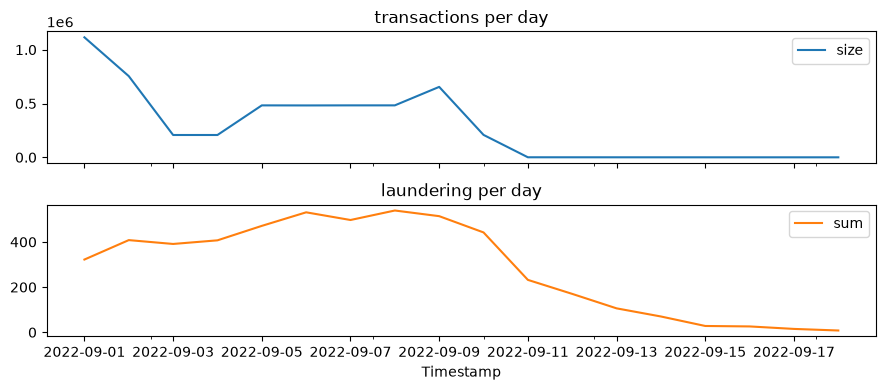

In [3]:
y = df["Is Laundering"].values
print(f"transactions {len(df):,}, laundering {y.sum():,} ({y.mean():.3%})")
print(df.groupby("Payment Format")["Is Laundering"].agg(["mean", "sum", "size"]).sort_values("mean", ascending=False))
daily = df.groupby(df["Timestamp"].dt.date)["Is Laundering"].agg(["size", "sum"])
daily.plot(subplots=True, figsize=(9, 4), title=["transactions per day", "laundering per day"]); plt.tight_layout(); plt.show()

## 문제 1: 한 행 = 거래 한 건

기준선 = 전부 '정상'. 규칙 하나 = 세탁 비율이 가장 높은 결제 형식이면 '세탁'.

In [4]:
def precision_recall(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1)); fp = np.sum((y_pred == 1) & (y_true == 0)); fn = np.sum((y_pred == 0) & (y_true == 1))
    return (tp / (tp + fp) if tp + fp else 0.0), tp / (tp + fn)

fmt = df.groupby("Payment Format")["Is Laundering"].mean().idxmax()
for name, pred in [("always normal", np.zeros(len(y), dtype=int)), (f"rule: {fmt}", (df["Payment Format"] == fmt).values.astype(int))]:
    p, r = precision_recall(y, pred)
    print(f"{name:16s} accuracy {np.mean(pred == y):.3%}  precision {p:.1%}  recall {r:.1%}")

always normal    accuracy 99.898%  precision 0.0%  recall 0.0%
rule: ACH        accuracy 88.244%  precision 0.7%  recall 86.6%


## 문제 2: 같은 파일, 한 행 = 보낸 계좌 하나

은행은 거래 하나하나를 막기보다 수상한 **계좌** 를 조사한다. 세탁 거래를 한 번이라도 보냈으면 1.

In [5]:
sender = df["From Bank"].astype(str) + "_" + df["Account"].astype(str)
acct = df.groupby(sender).agg(n_tx=("Is Laundering", "size"), y=("Is Laundering", "max"),
                              total=("Amount Paid", "sum"), n_formats=("Payment Format", "nunique"))
print(f"accounts {len(acct):,}, laundering accounts {acct['y'].sum():,} ({acct['y'].mean():.2%})")
print(f"rate: transaction level {y.mean():.3%}  ->  account level {acct['y'].mean():.2%}")
print(acct.groupby("y")[["n_tx", "n_formats"]].median())

accounts 496,999, laundering accounts 3,376 (0.68%)
rate: transaction level 0.102%  ->  account level 0.68%
   n_tx  n_formats
y                 
0   2.0        1.0
1   4.0        2.0


**관찰**: 같은 파일인데 한 행을 무엇으로 정하느냐에 따라 세탁 비율이 달라진다. 논문마다 '세탁 비율' 이 다르게 적힌 이유다.

## 다른 문제로 바꿔 보기

- **시간 순서**: 앞 날짜로 학습, 뒤 날짜로 시험해야 한다. 같은 계좌의 거래가 학습 · 시험 양쪽에 있으면?
- **그래프**: 세탁은 '돈이 계좌 여러 개를 돌아 다시 모이는' 모양 (원형, 부채꼴) 으로 나타난다. 한 행을 '거래' 가 아니라 '연결망의 모양' 으로 보면 그래프 신경망 (13주차) 문제가 된다. 원 논문이 이렇게 했다.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |